# Mathematical Notation in R

Statistics is written in mathematical notation: sums ($\sum$), products ($\prod$), subscripts ($x_i$), Greek letters ($\mu$, $\sigma$). This lesson shows two things:

1. **How common notation maps to R code** — so you can translate any formula from a textbook.
2. **How to display notation in plots** using R's `expression()` / *plotmath* system.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Translating Notation to R

| Notation | Meaning | R code |
|---|---|---|
| $x_i$ | $i$-th element | `x[i]` |
| $\sum_{i=1}^{n} x_i$ | sum | `sum(x)` |
| $\prod_{i=1}^{n} x_i$ | product | `prod(x)` |
| $\bar{x} = \frac{1}{n}\sum x_i$ | mean | `mean(x)` or `sum(x)/length(x)` |
| $\sum_{i=1}^{n} (x_i - \bar{x})^2$ | sum of squares | `sum((x - mean(x))^2)` |
| $n!$ | factorial | `factorial(n)` |
| $\binom{n}{k}$ | binomial coefficient | `choose(n, k)` |
| $\sqrt{x}$, $e^x$, $\ln x$, $\lvert x \rvert$ | functions | `sqrt(x)`, `exp(x)`, `log(x)`, `abs(x)` |
| $S_k = \sum_{i=1}^{k} x_i$ | running sum | `cumsum(x)` |

In [2]:
x <- c(4, 8, 15, 16, 23, 42)
n <- length(x)

cat("x_3                         =", x[3], "\n")
cat("sum_{i=1}^{n} x_i           =", sum(x), "\n")
cat("prod_{i=1}^{3} x_i          =", prod(x[1:3]), "\n")
cat("x-bar (manual)              =", sum(x) / n, " | mean(x) =", mean(x), "\n")
cat("sum (x_i - x-bar)^2         =", sum((x - mean(x))^2), "\n")
cat("sample variance s^2 (manual)=", sum((x - mean(x))^2) / (n - 1), " | var(x) =", var(x), "\n")
cat("5!                          =", factorial(5), "\n")
cat("C(6, 2)                     =", choose(6, 2), "\n")
cat("running sums S_k            =", cumsum(x), "\n")

x_3                         = 15 


sum_{i=1}^{n} x_i           = 108 


prod_{i=1}^{3} x_i          = 480 


x-bar (manual)              = 18  | mean(x) = 18 


sum (x_i - x-bar)^2         = 910 


sample variance s^2 (manual)= 182  | var(x) = 182 


5!                          = 120 


C(6, 2)                     = 15 


running sums S_k            = 4 12 27 43 66 108 


*Insight: Writing the formula manually and then comparing it with R's built-in function (`sum(...)/(n-1)` vs `var(x)`) is a great habit. It proves you understand the formula — and it reveals details like the $n-1$ denominator of the sample variance.*

## 2. Notation in Plots with `expression()`

R can display mathematical notation in plots, labels, and text using **expression syntax** (see `?plotmath`):

- Greek letters: `alpha`, `beta`, `mu`, `sigma`
- Superscript: `x^2`; subscript: `x[1]`
- Fractions: `frac(a, b)`; roots: `sqrt(x)`; sums: `sum(x[i], i==1, n)`
- `~` adds a space and `*` joins without space; `==` displays an equals sign
- Use `bquote()` to insert the *value* of an R variable into an expression: `bquote(mu == .(m))`

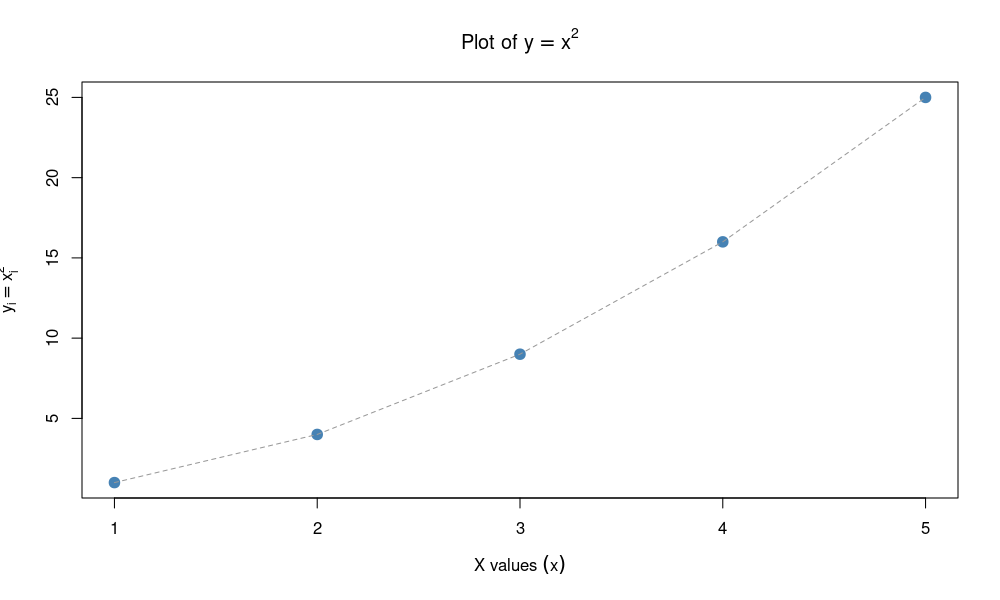

In [3]:
# Example: Displaying mathematical notation in a plot
x_vals <- 1:5
y_vals <- x_vals^2

plot(x_vals, y_vals, pch = 19, col = "steelblue", cex = 1.4,
     main = expression("Plot of" ~ y == x^2),
     xlab = expression("X values" ~ (x)),
     ylab = expression(y[i] == x[i]^2))
lines(x_vals, y_vals, col = "grey60", lty = 2)

## 3. A Richer Example: Annotating a Normal Density

Here we draw the normal density and annotate it with its formula, the mean $\mu$ and $\pm1\sigma$ markers — using `bquote()` so the labels show the actual numbers.

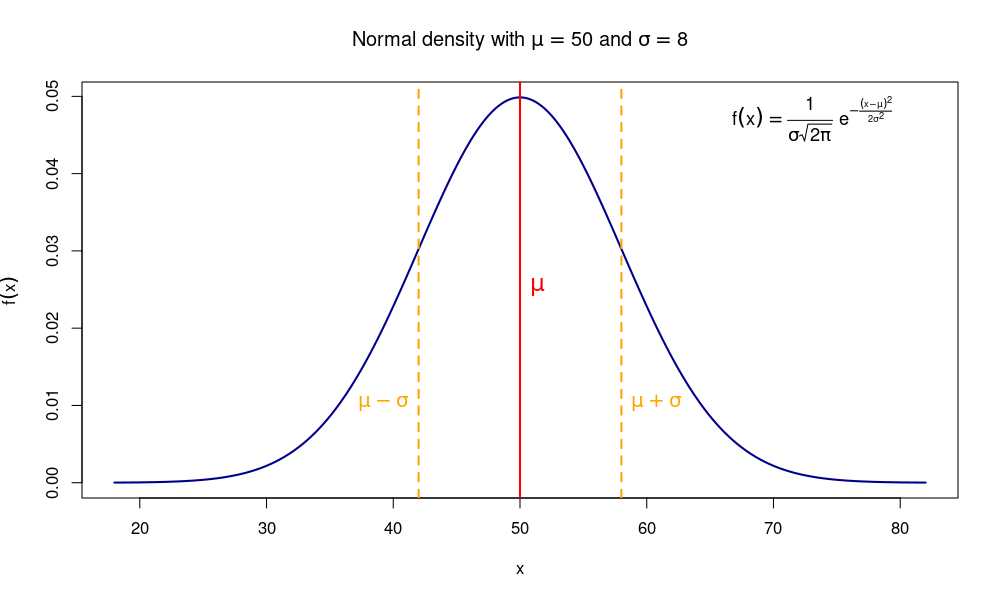

In [4]:
mu <- 50; sigma <- 8
xs <- seq(mu - 4 * sigma, mu + 4 * sigma, length.out = 400)

plot(xs, dnorm(xs, mu, sigma), type = "l", lwd = 2, col = "darkblue",
     main = bquote("Normal density with" ~ mu == .(mu) ~ "and" ~ sigma == .(sigma)),
     xlab = "x", ylab = expression(f(x)))
abline(v = mu, col = "red", lwd = 2)
abline(v = mu + c(-1, 1) * sigma, col = "orange", lty = 2, lwd = 2)

text(mu, dnorm(mu, mu, sigma) * 0.5, expression(mu), pos = 4, col = "red", cex = 1.4)
text(mu + sigma, dnorm(mu, mu, sigma) * 0.2, expression(mu + sigma), pos = 4, col = "orange", cex = 1.2)
text(mu - sigma, dnorm(mu, mu, sigma) * 0.2, expression(mu - sigma), pos = 2, col = "orange", cex = 1.2)

legend("topright", bty = "n", cex = 1.1,
       legend = expression(f(x) == frac(1, sigma * sqrt(2 * pi)) ~ e^{-frac((x - mu)^2, 2 * sigma^2)}))

*Insight: Markdown cells (like this one) render notation with LaTeX (`$\mu$`), while **plots** need R's own plotmath (`expression(mu)`). They look similar but are two separate systems — keep a `?plotmath` tab open while you learn.*

## Real-World Use Case or Analogy

Imagine you're preparing a math report for a class:
- You want to show that $y = x^2$ clearly in a plot title.
- You also want to label axes with subscripts and Greek letters for clarity.

Translating notation into R is like **reading sheet music and playing it on an instrument**: the formula ($\sum (x_i - \bar{x})^2$) is the score, and R code (`sum((x - mean(x))^2)`) is the performance. `expression()` goes the other way — it writes the score neatly onto your chart, just like you would on a blackboard.